In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch
import torch.nn as nn
from src.data import download_cifar10, show_samples, get_dataloaders
from src.models import VGGNet, VGG11_CONFIG
from src.metrics import count_parameters, print_param_summary

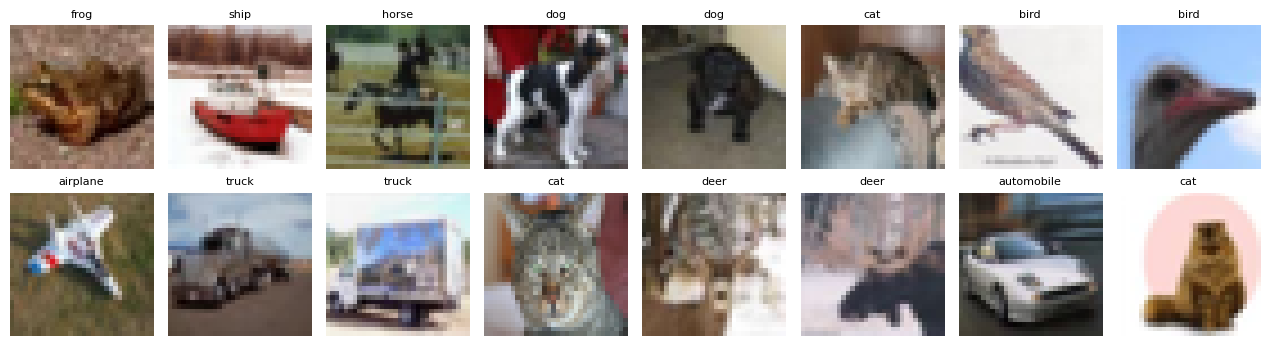

c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


torch.Size([128, 3, 32, 32]) torch.Size([128])
-0.18981994688510895 1.141002893447876


In [ ]:
# carichi dati
download_cifar10("../data")
show_samples("../data")

train_loader, val_loader, test_loader = get_dataloaders("../data")
x, y = next(iter(train_loader))
print(x.shape, y.shape)                      # [128, 3, 32, 32], [128]
print(x.mean().item(), x.std().item())       # ti aspetti circa ~0 e ~1 se la normalizzazione è giusta

In [3]:
from src.models import build_model
from src.metrics import count_parameters, print_param_summary

for name in ["teacher", "student"]:
    m = build_model(name).eval()
    c = count_parameters(m)
    assert c["total"] == sum(p.numel() for p in m.parameters())
    print_param_summary(c, name)
    with torch.no_grad():
        assert m(torch.rand(8, 3, 32, 32)).shape == (8, 10)

--- teacher params ---
Total:     15,530,762
conv       9,220,480 (59.37%)
linear     6,304,778 (40.60%)
bn         5,504 (0.04%)
--- student params ---
Total:     245,226
conv       144,560 (58.95%)
linear     99,978 (40.77%)
bn         688 (0.28%)
